# Laboratorio 4 - Segmentación de imágenes con técnicas de agrupación
### Caso DermAlpes

**Integrantes:**
- Samuel Molina Luna
- Daniel Pardo Pardo

## Descripción del laboratorio

**DermAlpes** es una empresa de telemedicina que conecta centros de salud de municipios pequeños con dermatólogos de las ciudades principales. En los centros de salud se toman fotografías de lesiones de piel con un dermatoscopio y se envían para que un especialista las revise a distancia. Para agilizar esa revisión, la empresa quiere una herramienta que **delimite automáticamente la zona de la lesión** en cada imagen, de modo que el dermatólogo pueda medir su tamaño y su forma y concentrar su atención en la región relevante.

DermAlpes no cuenta con imágenes etiquetadas de sus propios pacientes, así que como primera aproximación quiere evaluar si es posible segmentar la lesión **sin entrenar un modelo supervisado**, agrupando los píxeles de la imagen según su **color** y su **posición**. Para validar la idea, se construye un método de segmentación sobre un conjunto de imágenes públicas que sí incluye máscaras de referencia elaboradas por dermatólogos, y así se mide qué tan bien funciona, dónde falla y por qué.

La herramienta **no realiza diagnósticos**: su único propósito es delimitar la lesión como apoyo para el especialista. Aun así, la empresa quiere entender las limitaciones del método y los riesgos de usarlo con pacientes cuyas características difieran de las de las imágenes con que fue construido.

## Conjunto de datos

Para el conjunto de datos se utiliza una selección de 20 imágenes dermatoscópicas de ISIC 2016. Cada imagen viene acompañada de una máscara de referencia que identifica los píxeles correspondientes a la lesión. Estas máscaras no se usan para agrupar los píxeles sino que solo sirven para comparar y evaluar los resultados del método.

Las imágenes se dividen en dos conjuntos:

| Conjunto | Cantidad | Uso |
|---|---|---|
| **Ajuste** | 15 imágenes | Explorar y seleccionar la configuración del método comparando las máscaras estimadas con las de referencia |
| **Prueba** | 5 imágenes | Evaluar el desempeño final sin realizar modificaciones adicionales |

| Imágenes de ajuste | | | Imágenes de prueba |
|---|---|---|---|
| ISIC_0000085 | ISIC_0000114 | ISIC_0000150 | ISIC_0000087 |
| ISIC_0000086 | ISIC_0000116 | ISIC_0000153 | ISIC_0000105 |
| ISIC_0000089 | ISIC_0000122 | ISIC_0000156 | ISIC_0000110 |
| ISIC_0000094 | ISIC_0000133 | ISIC_0000157 | ISIC_0000123 |
| ISIC_0000108 | ISIC_0000137 | ISIC_0000112 | ISIC_0000128 |

**Preparación de las máscaras.** Las máscaras originales contienen los valores 0 (piel o fondo) y 255 (lesión), que se convierten a 0 y 1. Si se reduce el tamaño de las imágenes, las máscaras se redimensionan con interpolación por vecino más cercano para conservar sus valores binarios.

**Fuente.** International Skin Imaging Collaboration (ISIC), *ISIC 2016 Challenge - Task 1: Lesion Segmentation*. Disponible en: https://challenge.isic-archive.com/landing/2016/37/

Referencia del desafío: Gutman, D., Codella, N. C. F., Celebi, E., et al. (2016). *Skin Lesion Analysis toward Melanoma Detection: A Challenge at the International Symposium on Biomedical Imaging (ISBI) 2016, hosted by the International Skin Imaging Collaboration (ISIC)*. arXiv:1605.01397.

# Importación de librerías

Se importan las librerías que se usan a lo largo del laboratorio: NumPy y pandas para los datos y las tablas de resultados, Pillow para leer las imágenes, Matplotlib y Seaborn para las visualizaciones, y Scikit-learn para el pipeline, K-medias y las métricas (silueta, Dice a través de `f1_score`, V-measure, precisión y recall).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import cv2
from glob import glob

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, f1_score, v_measure_score,
                             precision_score, recall_score)

## Pipeline

In [2]:
import os

ids_ajuste = ['ISIC_0000085','ISIC_0000086','ISIC_0000089','ISIC_0000094','ISIC_0000108',
              'ISIC_0000114','ISIC_0000116','ISIC_0000122','ISIC_0000133','ISIC_0000137',
              'ISIC_0000150','ISIC_0000153','ISIC_0000156','ISIC_0000157','ISIC_0000112']
ids_prueba = ['ISIC_0000087','ISIC_0000105','ISIC_0000110','ISIC_0000123','ISIC_0000128']

RUTA_IMAGENES = 'data/imagenes'
RUTA_MASCARAS = 'data/mascaras'

print(len(os.listdir(RUTA_IMAGENES)), 'imágenes')
print(len(os.listdir(RUTA_MASCARAS)), 'máscaras')

faltan = [i for i in ids_ajuste + ids_prueba
          if not os.path.exists(f'{RUTA_IMAGENES}/{i}.jpg')
          or not os.path.exists(f'{RUTA_MASCARAS}/{i}_Segmentation.png')]
print('Faltantes:', faltan)

20 imágenes
20 máscaras
Faltantes: []


## 1. Pipeline de representacion y agrupacion

**1.1 Carga de imagenes y mascaras**

Primero cada imagen se redimensiona para que su lado mayor mida `MAX_LADO` pixeles lo que conserva la proporcion con el fin de reducir el costo de K-means. La mascara tambien se redimensiona al mismo tamaño con interpolacion de vecino mas cercano para no crear valores intermedios y se convierte de 0/255 a 0/1 (1 = lesion).

In [4]:
MAX_LADO = 128

def cargar_par(id_img, max_lado=MAX_LADO):
    img = cv2.imread(f'{RUTA_IMAGENES}/{id_img}.jpg', cv2.IMREAD_COLOR_RGB)
    mask = cv2.imread(f'{RUTA_MASCARAS}/{id_img}_Segmentation.png', cv2.IMREAD_GRAYSCALE)
    factor = max_lado / max(img.shape[:2])
    nuevo = (round(img.shape[1] * factor), round(img.shape[0] * factor))  # (ancho, alto)
    img = cv2.resize(img, nuevo, interpolation=cv2.INTER_AREA)
    mask = cv2.resize(mask, nuevo, interpolation=cv2.INTER_NEAREST)
    return img, (mask > 127).astype(int)

imagenes, mascaras = {}, {}
for id_img in ids_ajuste + ids_prueba:
    imagenes[id_img], mascaras[id_img] = cargar_par(id_img)

resumen = pd.DataFrame({
    'id': list(imagenes.keys()),
    'grupo': ['ajuste'] * len(ids_ajuste) + ['prueba'] * len(ids_prueba),
    'alto': [imagenes[i].shape[0] for i in imagenes],
    'ancho': [imagenes[i].shape[1] for i in imagenes],
    'valores_mascara': [sorted(np.unique(mascaras[i]).tolist()) for i in imagenes],
    '%_lesion': [round(100 * mascaras[i].mean(), 1) for i in imagenes],
})
resumen[resumen['grupo'] == 'ajuste']

,id,grupo,alto,ancho,valores_mascara,%_lesion
0,ISIC_0000085,ajuste,96,128,"[0, 1]",12.7
1,ISIC_0000086,ajuste,96,128,"[0, 1]",23.4
2,ISIC_0000089,ajuste,96,128,"[0, 1]",12.1
3,ISIC_0000094,ajuste,96,128,"[0, 1]",5.9
4,ISIC_0000108,ajuste,96,128,"[0, 1]",18.5
5,ISIC_0000114,ajuste,96,128,"[0, 1]",3.1
6,ISIC_0000116,ajuste,96,128,"[0, 1]",36.1
7,ISIC_0000122,ajuste,96,128,"[0, 1]",39.1
8,ISIC_0000133,ajuste,96,128,"[0, 1]",14.2
9,ISIC_0000137,ajuste,96,128,"[0, 1]",24.4


**1.2 Representacion por pixel y pipeline**

Cada imagen $H \times W \times 3$ se convierte en una matriz de $H \cdot W$ filas (un pixel por fila) con las caracteristicas $[\beta R, \beta G, \beta B, \lambda x, \lambda y]$, donde R, G, B se dividen por 255 y las coordenadas $x, y$ por $W-1$ y $H-1$, de modo que todas queden en $[0, 1]$. Solo importa la razón $\lambda/\beta$, porque K-means depende de las distancias relativas. Con $\lambda = 0$ se usa solo color y con $\beta = 0$ solo posición. Con esto el pipeline tiene dos pasos: la representacion (con β y λ como parametros) y K-means.

Forma de X: (12288, 5)


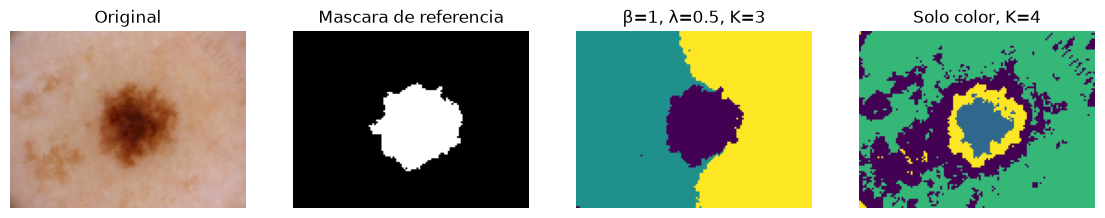

In [6]:
def representar_pixeles(imagen, beta=1.0, lam=1.0):
    alto, ancho, _ = imagen.shape
    color = imagen.reshape(-1, 3) / 255.0
    I, J = np.meshgrid(np.arange(alto), np.arange(ancho), indexing='ij')
    y = I.ravel() / (alto - 1)
    x = J.ravel() / (ancho - 1)
    return np.column_stack([beta * color, lam * x, lam * y])

def construir_pipeline(beta, lam, k, semilla=42):
    return Pipeline(steps=[
        ('representacion', FunctionTransformer(representar_pixeles,
                                               kw_args={'beta': beta, 'lam': lam})),
        ('kmeans', KMeans(n_clusters=k, n_init=10, random_state=semilla))
    ])

# Prueba rapida con una imagen de ajuste
id_demo = 'ISIC_0000085'
img_demo = imagenes[id_demo]

pipe = construir_pipeline(beta=1.0, lam=0.5, k=3)
etiquetas = pipe.fit_predict(img_demo).reshape(img_demo.shape[:2])

# Cambiar β, λ o K sin tocar la implementacion
pipe.set_params(representacion__kw_args={'beta': 1.0, 'lam': 0.0}, kmeans__n_clusters=4)
etiquetas_color = pipe.fit_predict(img_demo).reshape(img_demo.shape[:2])

print('Forma de X:', pipe[:-1].transform(img_demo).shape)

fig, ax = plt.subplots(1, 4, figsize=(14, 4))
ax[0].imshow(img_demo);               ax[0].set_title('Original')
ax[1].imshow(mascaras[id_demo], cmap='gray'); ax[1].set_title('Mascara de referencia')
ax[2].imshow(etiquetas);              ax[2].set_title('β=1, λ=0.5, K=3')
ax[3].imshow(etiquetas_color);        ax[3].set_title('Solo color, K=4')
for a in ax: a.axis('off')
plt.show()